<a href="https://colab.research.google.com/github/mrayhanz/PCVK-Ganjil-2026/blob/main/week9_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

Kelas : TI - 3G

Nim : 244107020027

Absen : 19

In [ ]:
NAMA = 'Muhammad Rayhan Zamzami'
NIM = '244107020027' # ganti dengan NIM sendiri
print(NAMA, NIM)

Muhammad Rayhan Zamzami 244107020027


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import Library
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, segmentation
from sklearn.cluster import KMeans
BASE = '/content/drive/MyDrive/PCVK-2026/Images'

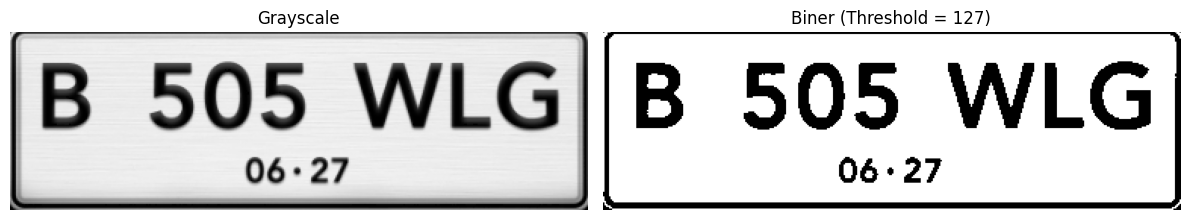

Berhasil disimpan: /content/drive/MyDrive/PCVK-2026/Images/plat_binary.png


In [ ]:
# Baca gambar sebagai grayscale
gray = cv.imread(
    '/content/drive/MyDrive/PCVK-2026/Images/plat-nomor-kendaraan.png',
    cv.IMREAD_GRAYSCALE
)

if gray is None:
    raise FileNotFoundError('Gambar tidak ditemukan. Periksa lokasi file.')

# Thresholding → citra biner
_, binary = cv.threshold(gray, 127, 255, cv.THRESH_BINARY)

# Tampilkan hasil
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray', vmin=0, vmax=255)
plt.title('Grayscale')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap='gray', vmin=0, vmax=255)
plt.title('Biner (Threshold = 127)')
plt.axis('off')

plt.tight_layout()
plt.show()

output_path = '/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png'

if cv.imwrite(output_path, binary):
    print('Berhasil disimpan:', output_path)
else:
    raise IOError('Gagal menyimpan gambar.')

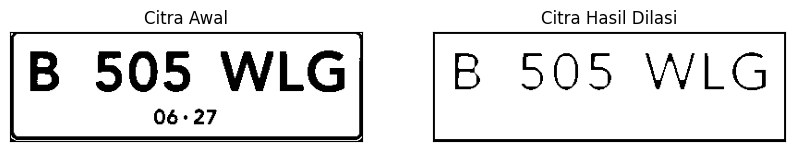

In [ ]:
#Dilasi tanpa library
def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= np.ones((w,w), dtype=np.uint8)
  constant1= (w-1)//2
  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

img_d= cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png',0)
ret, thresh = cv.threshold(img_d, 125, 200, cv.THRESH_BINARY)
w=5
imgD = dilasi_citra(thresh,w)

plt.figure(figsize=(10, 5))
plt.subplot(121),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


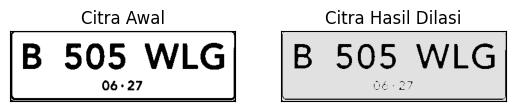

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png')
#img = cv.imread('morp.jpg',0)
ret, thresh = cv.threshold(img, 127, 225, cv.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv.dilate(thresh,kernel,iterations = 1)
print(kernel)

plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

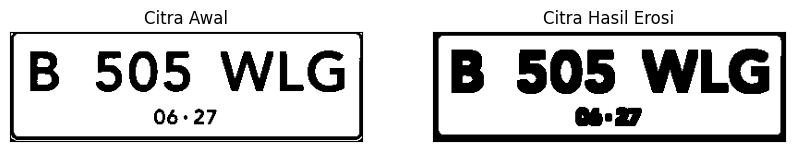

In [ ]:
#Erosi Tanpa Library
def erosi_citra(F,k):
  #size image
  m,n= F.shape
  #Generate structure element erosi (SE)
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)
  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE

img_e= cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png',0)
ret1, thresh1 = cv.threshold(img_e, 175, 225, cv.THRESH_BINARY)
k=5
imgE = erosi_citra(thresh1,k)

plt.figure(figsize=(10, 5))
plt.subplot(121),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

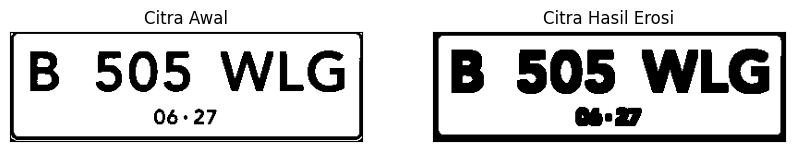

In [ ]:
#EROSI LIBRARY
img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png')
kernel = np.ones((5,5),np.uint8)
erosion = cv.erode(img,kernel,iterations = 1)

plt.figure(figsize=(10, 5))
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

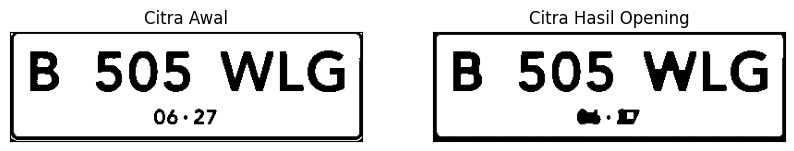

In [ ]:
img_o = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)
reto, thresho = cv.threshold(img_o, 127, 255, cv.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

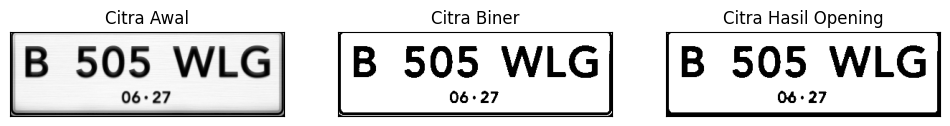

In [ ]:
#Dengan Menggunakan Library
img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat-nomor-kendaraan.png',0)
ret, thresh = cv.threshold(img, 127, 255, cv.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
openn = cv.morphologyEx(thresh,cv.MORPH_OPEN, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(openn,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

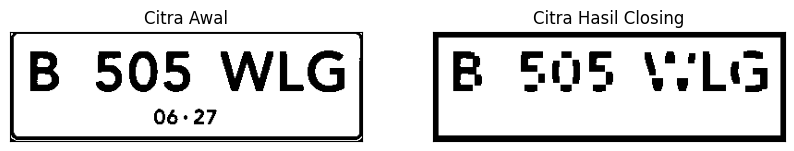

In [ ]:
img_c = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)
retc, threshc = cv.threshold(img_c, 127, 255, cv.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

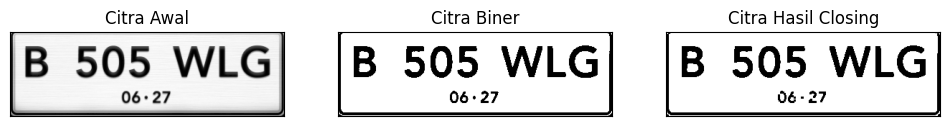

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat-nomor-kendaraan.png',0)
ret, thresh = cv.threshold(img, 127, 255, cv.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
closs = cv.morphologyEx(thresh,cv.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(closs,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 3


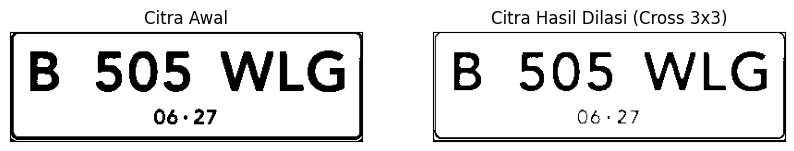

SED = Cross 5


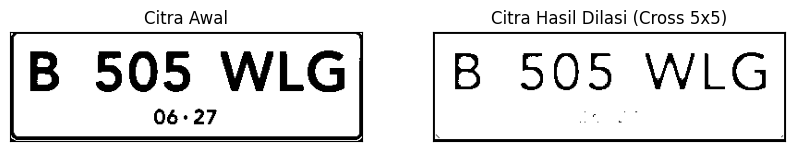

In [ ]:
# Dilasi Cross SED 3x3
def dilasi_citra_cross3(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([
        [0, 1, 0],
        [1, 1, 1],
        [0, 1, 0]
    ], dtype=np.uint8)

    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 3')
img_d = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)
ret, thresh = cv.threshold(img_d, 127, 255, cv.THRESH_BINARY)
w = 3
imgD3 = dilasi_citra_cross3(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD3, cmap='gray')
plt.title('Citra Hasil Dilasi (Cross 3x3)'), plt.xticks([]), plt.yticks([])
plt.show()

# Dilasi Cross SED 5x5
def dilasi_citra_cross5(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([
        [0, 0, 1, 0, 0],
        [0, 0, 1, 0, 0],
        [1, 1, 1, 1, 1],
        [0, 0, 1, 0, 0],
        [0, 0, 1, 0, 0]
    ], dtype=np.uint8)

    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 5')
w = 5
imgD5 = dilasi_citra_cross5(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD5, cmap='gray')
plt.title('Citra Hasil Dilasi (Cross 5x5)'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Circle 3


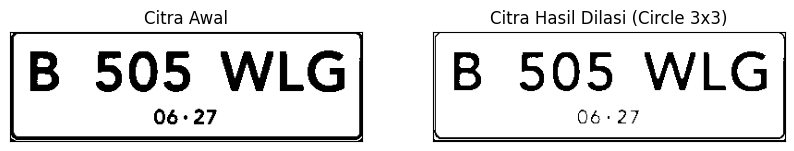

SED = Circle 5


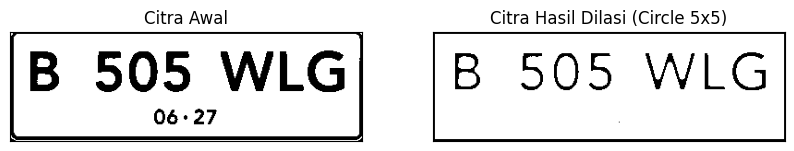

In [ ]:
# Dilasi Circular SED 3x3
def dilasi_citra_circle(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = cv.getStructuringElement(cv.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Circle 3')
img_d = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)
ret, thresh = cv.threshold(img_d, 127, 255, cv.THRESH_BINARY)
w = 3
imgD3 = dilasi_citra_circle(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD3, cmap='gray')
plt.title('Citra Hasil Dilasi (Circle 3x3)'), plt.xticks([]), plt.yticks([])
plt.show()

print('SED = Circle 5')
w = 5
imgD5 = dilasi_citra_circle(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD5, cmap='gray')
plt.title('Citra Hasil Dilasi (Circle 5x5)'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Rectangle 3x5


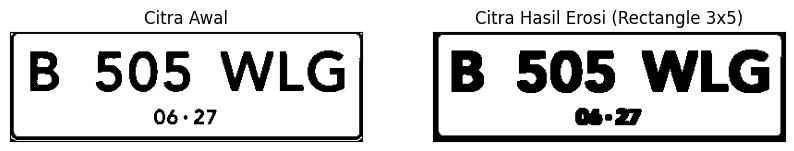

SE = Rectangle 5x7


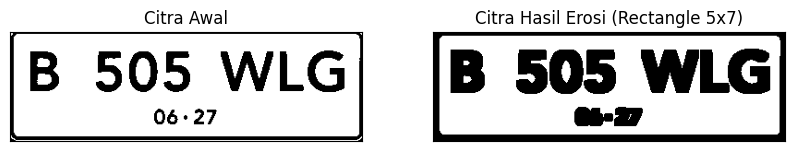

In [ ]:
# Erosi Rectangle SE
def erosi_citra_rect(F, p, l):
    m, n = F.shape
    SE = cv.getStructuringElement(cv.MORPH_RECT, (p, l))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Rectangle 3x5')
img_e = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)
ret1, thresh1 = cv.threshold(img_e, 127, 255, cv.THRESH_BINARY)
p = 5
l = 3
imgE_rect35 = erosi_citra_rect(thresh1, p, l)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE_rect35, cmap='gray')
plt.title('Citra Hasil Erosi (Rectangle 3x5)'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Rectangle 5x7')
p = 7
l = 5
imgE_rect57 = erosi_citra_rect(thresh1, p, l)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE_rect57, cmap='gray')
plt.title('Citra Hasil Erosi (Rectangle 5x7)'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Line Vertikal 3


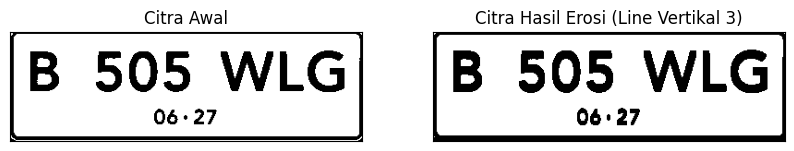

SE = Line Vertikal 5


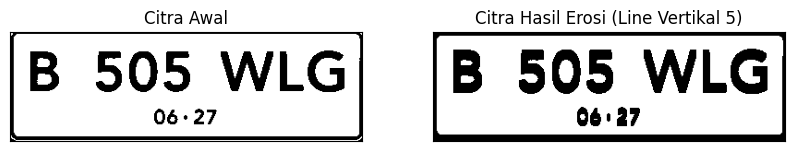

In [ ]:
# Erosi Line Vertikal SE
def erosi_citra_line(F, k):
    m, n = F.shape
    SE = cv.getStructuringElement(cv.MORPH_RECT, (1, k))
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(n):
            temp = F[i - constant:i + constant + 1, j:j + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Line Vertikal 3')
img_e = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)
ret1, thresh1 = cv.threshold(img_e, 127, 255, cv.THRESH_BINARY)
k = 3
imgE_line3 = erosi_citra_line(thresh1, k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE_line3, cmap='gray')
plt.title('Citra Hasil Erosi (Line Vertikal 3)'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Line Vertikal 5')
k = 5
imgE_line5 = erosi_citra_line(thresh1, k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE_line5, cmap='gray')
plt.title('Citra Hasil Erosi (Line Vertikal 5)'), plt.xticks([]), plt.yticks([])
plt.show()

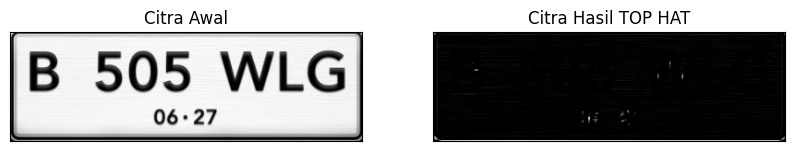

In [ ]:
# Transformasi Top-Hat
filterSize = (3, 3)
kernel = cv.getStructuringElement(cv.MORPH_RECT, filterSize)

img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat-nomor-kendaraan.png', 0)
if img is None:
    img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)

tophat_img = cv.morphologyEx(img, cv.MORPH_TOPHAT, kernel)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

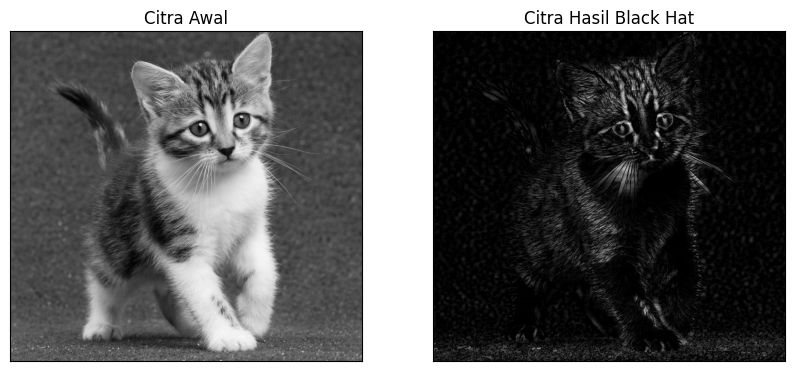

In [ ]:
# Transformasi Black-Hat
filterSize = (3, 3)
kernel = cv.getStructuringElement(cv.MORPH_RECT, filterSize)

img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/kitten01.jpg')
if img is not None:
    img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
else:
    img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat-nomor-kendaraan.png', 0)

Kernel = cv.getStructuringElement(cv.MORPH_RECT, (13, 5))
blackhat = cv.morphologyEx(img, cv.MORPH_BLACKHAT, Kernel)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

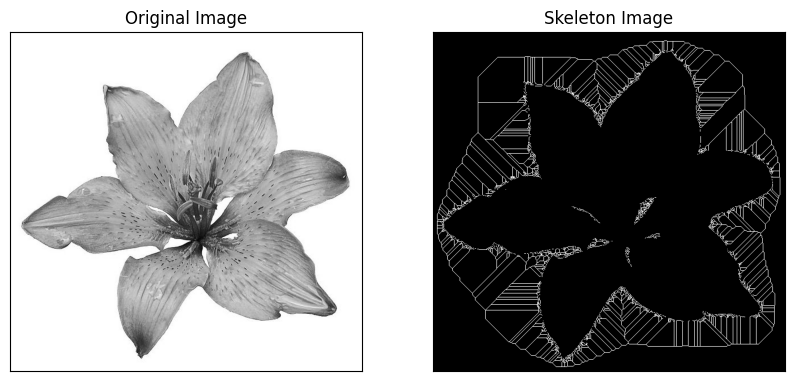

In [ ]:
# Skeleton Citra Biner
from skimage import filters
from skimage.morphology import skeletonize

img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/lily.jpg', 0)
if img is None:
    img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)

binary = img > filters.threshold_triangle(img)
binary_cp = binary.copy().astype(np.uint8)

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image'), plt.xticks([]), plt.yticks([])
plt.show()

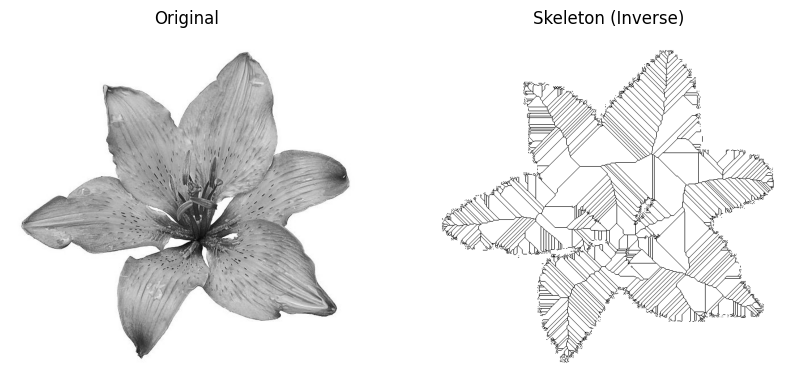

In [ ]:
# Skeleton Citra Inversi
from skimage import io, filters
from skimage.morphology import skeletonize

img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/lily.jpg', 0)
if img is None:
    img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)

binary = img < filters.threshold_triangle(img)
skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original')
ax[0].axis('off')

ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('Skeleton (Inverse)')
ax[1].axis('off')
plt.show()

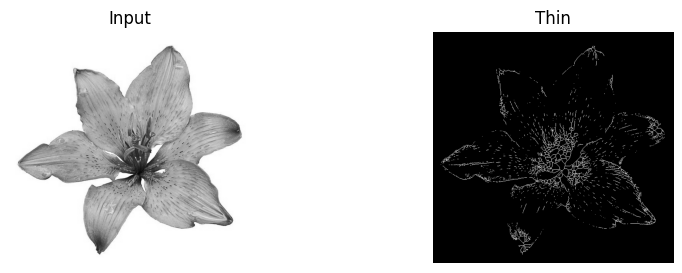

In [ ]:
# Thinning
from skimage import img_as_float, color, morphology

img = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/lily.jpg')
if img is not None:
    image = img_as_float(cv.cvtColor(img, cv.COLOR_BGR2GRAY))
else:
    img_gray = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)
    image = img_as_float(img_gray)

image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax0.axis('off')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
ax1.axis('off')
plt.show()

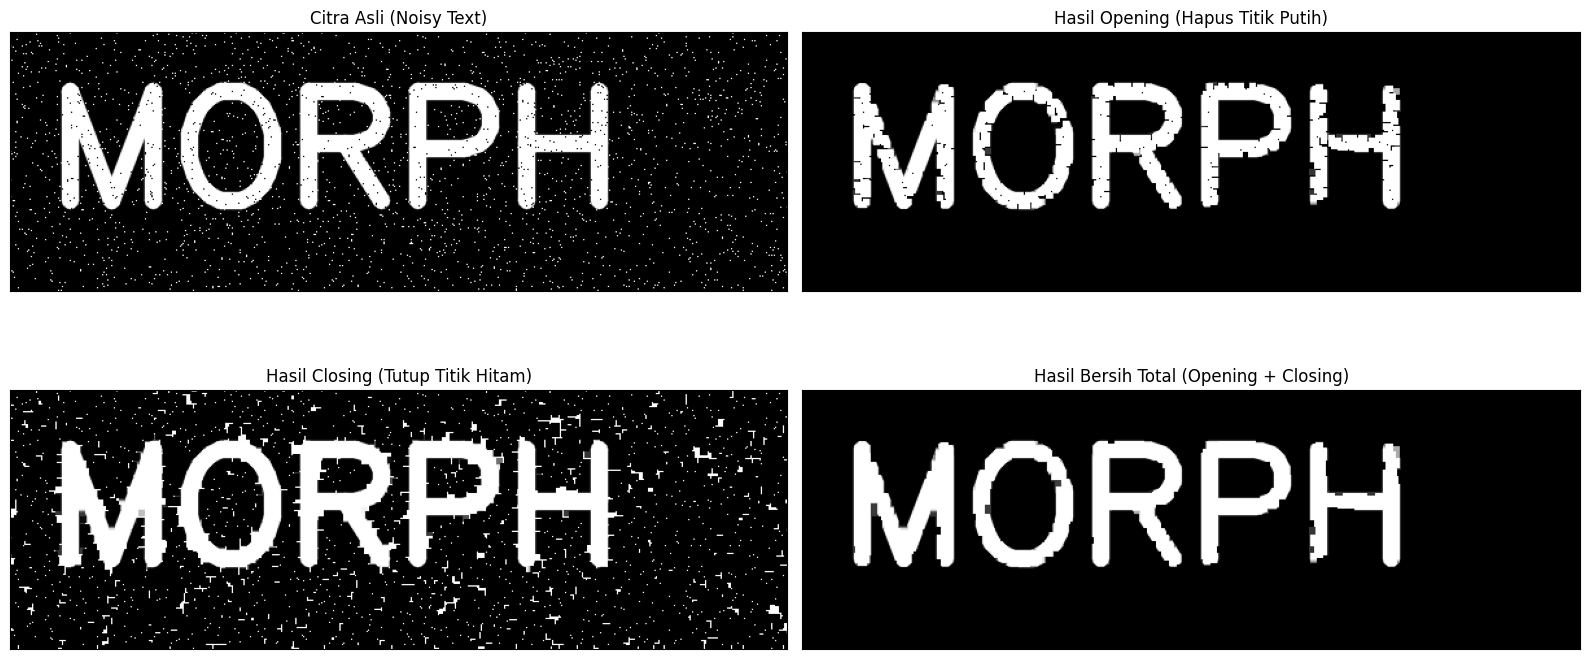

In [ ]:
# Penerapan Morfologi pada Noisy Text
noisy = cv.imread('/content/drive/MyDrive/PCVK-2026/noises/noisy_text.png', 0)
if noisy is None:
    noisy = cv.imread('/content/drive/MyDrive/PCVK-2026/noises/noisy_text.png')
    if noisy is not None:
        noisy = cv.cvtColor(noisy, cv.COLOR_BGR2GRAY)

kernel = np.ones((5, 5), np.uint8)

# 1. Opening untuk menghilangkan noise di latar (bintik putih)
noisy_opening = cv.morphologyEx(noisy, cv.MORPH_OPEN, kernel)

# 2. Closing untuk menutup noise di dalam huruf (lubang hitam)
noisy_closing = cv.morphologyEx(noisy, cv.MORPH_CLOSE, kernel)

# 3. Opening lalu Closing untuk hasil bersih total
noisy_clean = cv.morphologyEx(noisy_opening, cv.MORPH_CLOSE, kernel)

plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(noisy, cmap='gray')
plt.title('Citra Asli (Noisy Text)'), plt.xticks([]), plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(noisy_opening, cmap='gray')
plt.title('Hasil Opening (Hapus Titik Putih)'), plt.xticks([]), plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(noisy_closing, cmap='gray')
plt.title('Hasil Closing (Tutup Titik Hitam)'), plt.xticks([]), plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(noisy_clean, cmap='gray')
plt.title('Hasil Bersih Total (Opening + Closing)'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

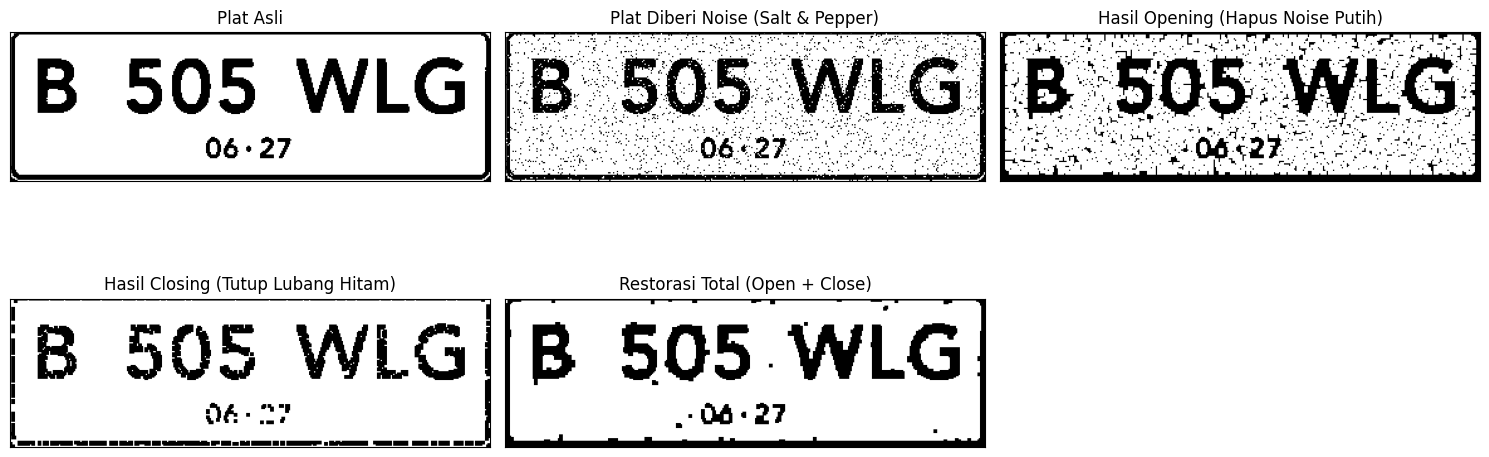

In [ ]:
# Simulasi Noise Salt & Pepper pada Citra Plat Nomor dan Restorasi Morfologi
plat = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat_binary.png', 0)
if plat is None:
    plat = cv.imread('/content/drive/MyDrive/PCVK-2026/Images/plat-nomor-kendaraan.png', 0)
    _, plat = cv.threshold(plat, 127, 255, cv.THRESH_BINARY)

# Beri Salt and Pepper Noise ke citra plat nomor
noisy_plat = plat.copy()
h, w = noisy_plat.shape
prob = 0.05
num_noise = int(prob * h * w)

# 1. Salt noise: bintik putih di latar hitam
for _ in range(num_noise):
    y = np.random.randint(0, h)
    x = np.random.randint(0, w)
    noisy_plat[y, x] = 255

# 2. Pepper noise: lubang hitam di objek huruf putih
for _ in range(num_noise):
    y = np.random.randint(0, h)
    x = np.random.randint(0, w)
    noisy_plat[y, x] = 0

# Operasi Morfologi untuk menghilangkan noise
kernel = np.ones((3, 3), np.uint8)

# Opening: hapus bintik putih di luar huruf
plat_open = cv.morphologyEx(noisy_plat, cv.MORPH_OPEN, kernel)

# Closing: tutup lubang hitam di dalam huruf
plat_close = cv.morphologyEx(noisy_plat, cv.MORPH_CLOSE, kernel)

# Restorasi total: Opening lalu Closing
plat_restored = cv.morphologyEx(plat_open, cv.MORPH_CLOSE, kernel)

# Tampilkan visualisasi
plt.figure(figsize=(15, 6))

plt.subplot(2, 3, 1)
plt.imshow(plat, cmap='gray')
plt.title('Plat Asli'), plt.xticks([]), plt.yticks([])

plt.subplot(2, 3, 2)
plt.imshow(noisy_plat, cmap='gray')
plt.title('Plat Diberi Noise (Salt & Pepper)'), plt.xticks([]), plt.yticks([])

plt.subplot(2, 3, 3)
plt.imshow(plat_open, cmap='gray')
plt.title('Hasil Opening (Hapus Noise Putih)'), plt.xticks([]), plt.yticks([])

plt.subplot(2, 3, 4)
plt.imshow(plat_close, cmap='gray')
plt.title('Hasil Closing (Tutup Lubang Hitam)'), plt.xticks([]), plt.yticks([])

plt.subplot(2, 3, 5)
plt.imshow(plat_restored, cmap='gray')
plt.title('Restorasi Total (Open + Close)'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

In [ ]:
!jupyter nbconvert --to html "/content/drive/MyDrive/PCVK-2026/week9_19.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/PCVK-2026/week9_19.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 24 image(s).
[NbConvertApp] Writing 2379012 bytes to /content/drive/MyDrive/PCVK-2026/week9_19.html
